# 03 SD visual - latente 64x64 vs pixel 512x512 (punto 3)


Consigna: extraer tensores manualmente con diffusers, ver VAE + UNet + texto. Si el modelo pide login, agrega HF_TOKEN en Colab Secrets.


### Setup (apuntes REPOS 3.2: solo diffusers+transformers)
Instalamos lo minimo. Ver REPOS_ESTADO 3.1.


In [1]:
%pip install -q diffusers transformers accelerate
import torch
print(torch.cuda.is_available())


True


### Token HF (apuntes NOTAS 05 LDM)
SD v1.5 es gated. Sin token da 401. Pon HF_TOKEN en Secrets Colab.


In [2]:
import os
from huggingface_hub import login

tok = os.environ.get("HF_TOKEN", "")
if tok:
    login(token=tok)
    print("token: cargado")
else:
    print("token: no configurado; si el modelo pide login, agrega HF_TOKEN en Colab Secrets")
# En Colab: from google.colab import userdata; login(userdata.get("HF_TOKEN"))

token: no configurado; si el modelo pide login, agrega HF_TOKEN en Colab Secrets


### Componentes SD (apuntes NOTAS 05 + paper 2112.10752)
VAE f=8 comprime 512->64, UNet denoisea en latente, CLIP 77x768 condiciona por cross-attn, scheduler DDIM 50.


In [3]:
import torch
from diffusers import StableDiffusionPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    dtype=dtype,
)
pipe = pipe.to(device)
print("device:", device, "| dtype:", dtype)
print("componentes:", list(pipe.components.keys()))
print("VAE sample_size:", pipe.vae.config.sample_size, "| UNet sample_size:", pipe.unet.config.sample_size)
print("scaling_factor:", pipe.vae.config.scaling_factor)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

device: cuda | dtype: torch.float16
componentes: ['vae', 'text_encoder', 'tokenizer', 'unet', 'scheduler', 'safety_checker', 'feature_extractor', 'image_encoder']
VAE sample_size: 512 | UNet sample_size: 64
scaling_factor: 0.18215


### Generacion + extraccion manual (apuntes NOTAS punto3)
Callback guarda latents (1,4,64,64) cada step. Es el tensor manual que pide la consigna.


  0%|          | 0/50 [00:00<?, ?it/s]

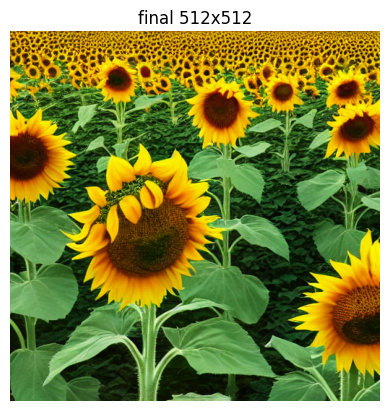

steps guardados: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] lat shape: torch.Size([1, 4, 64, 64])


In [4]:
prompt = "a close-up photo of a sunflower field, high detail"
import torch, matplotlib.pyplot as plt

saved = {}
def cb(pipe, step, t, cb_kwargs):
    saved[step] = cb_kwargs["latents"].detach().float().cpu()
    return cb_kwargs

img = pipe(
    prompt,
    num_inference_steps=50,
    guidance_scale=7.5,
    callback_on_step_end=cb,
    callback_on_step_end_tensor_inputs=["latents"],
).images[0]
plt.imshow(img); plt.title("final 512x512"); plt.axis("off"); plt.show()
print("steps guardados:", sorted(saved.keys())[:10], "lat shape:", list(saved.values())[0].shape)

### Latente vs pixel (consigna punto3 + NOTAS 05)
Heatmap promedio 4 canales 64x64 arriba, decode VAE abajo 512x512. f=8: 64*8=512.


steps: [0, 10, 20, 30, 40, 50] | scaling_factor: 0.18215


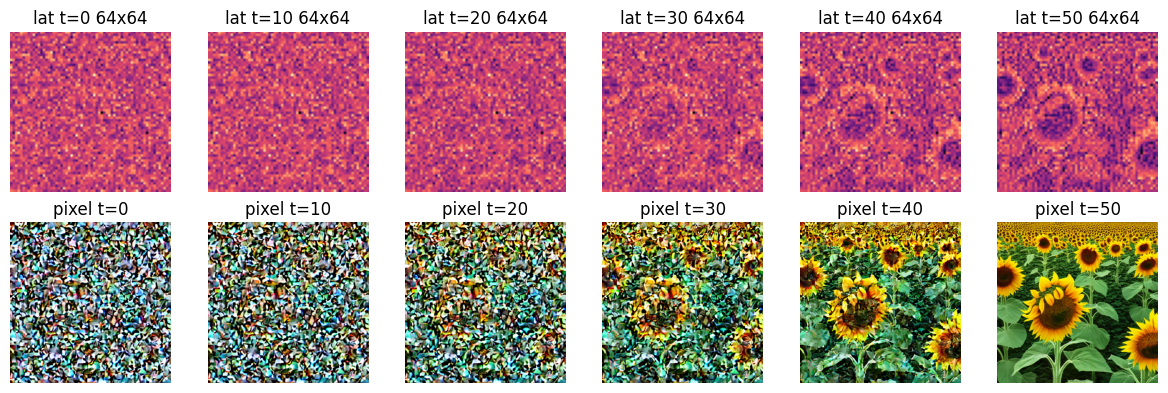

VAE: factor f=8, 64*8=512; latentes divididos por scaling_factor antes de decodificar


In [5]:
# Latente 64x64x4 vs pixel 512x512: promedia canales -> heatmap + decode con VAE.
import torch, matplotlib.pyplot as plt

all_steps = sorted(saved)
steps = [all_steps[round(i * (len(all_steps) - 1) / 5)] for i in range(6)]
scale = pipe.vae.config.scaling_factor  # 0.18215 en SD v1.5
print("steps:", steps, "| scaling_factor:", scale)

plt.figure(figsize=(12, 4))
for k, s in enumerate(steps):
    lat = saved[s][0] / scale  # los latentes del pipeline estan escalados
    hm = lat.mean(0).numpy()
    plt.subplot(2, 6, k + 1)
    plt.imshow(hm, cmap="magma")
    plt.title(f"lat t={s} 64x64")
    plt.axis("off")
    with torch.no_grad():
        dec = pipe.vae.decode(lat.unsqueeze(0).to(pipe.vae.dtype).to(pipe.device)).sample[0]
        dec = (dec / 2 + 0.5).clamp(0, 1).permute(1, 2, 0).float().cpu().numpy()
    plt.subplot(2, 6, k + 7)
    plt.imshow(dec)
    plt.title(f"pixel t={s}")
    plt.axis("off")
plt.tight_layout(); plt.show()
print("VAE: factor f=8, 64*8=512; latentes divididos por scaling_factor antes de decodificar")

### Texto -> UNet (apuntes NOTAS 06 CFG + 23 SD3)
Tokens 77 + emb 77x768 entran a UNet por cross-attention. guidance_scale=7.5.


tokens: torch.Size([1, 77])
text_emb: (1, 77, 768) -> entra a UNet via cross-attn


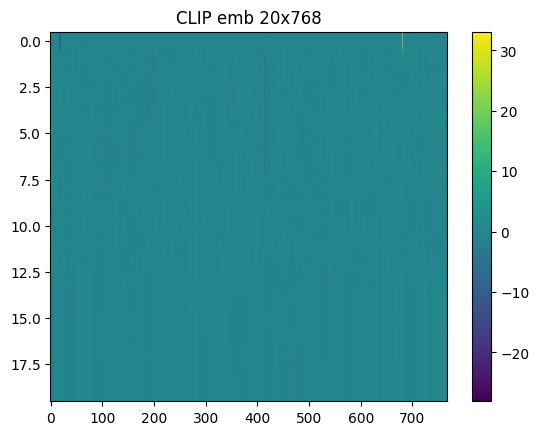

In [6]:
# tensores texto: CLIP -> UNet cross-attention
toks=pipe.tokenizer(prompt, padding="max_length", max_length=77, return_tensors="pt")
print("tokens:", toks.input_ids.shape)
emb=pipe.text_encoder(toks.input_ids.to(pipe.device))[0]
print("text_emb:", tuple(emb.shape), "-> entra a UNet via cross-attn")
import matplotlib.pyplot as plt
plt.imshow(emb[0,:20,:].detach().float().cpu().numpy(), aspect="auto"); plt.title("CLIP emb 20x768"); plt.colorbar(); plt.show()


### Proceso (consigna: visualizar proceso)
Norma latente vs step: ruido->senal. Complementa grid 6 pasos.


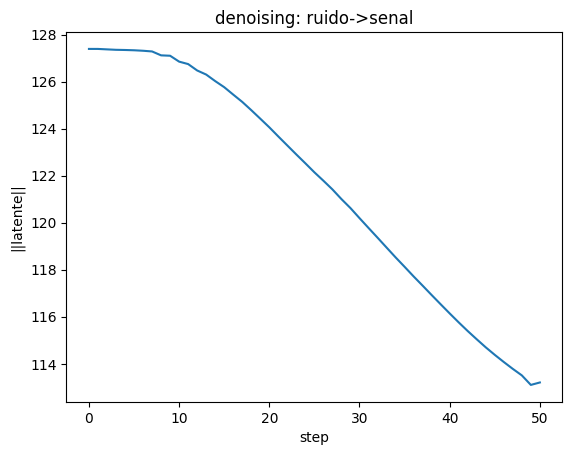

In [7]:
# curva denoising: norma del latente vs step
import matplotlib.pyplot as plt
xs=sorted(saved.keys())
ys=[float(saved[s].norm()) for s in xs]
plt.plot(xs,ys); plt.xlabel("step"); plt.ylabel("||latente||"); plt.title("denoising: ruido->senal"); plt.show()


## Para informe: VAE comprime 512->64 (f=8), UNet denoisea en el latente y el texto entra por CLIP. Los latentes del pipeline estan escalados por 0.18215; se dividen antes de decodificar. DDIM 50 pasos: ruido -> estructura -> imagen.
